# Linear Regression — House Prices, Metrics, Scaling, the Matrix Method, Ridge, and Lasso

A beginner-friendly companion to the teaching notes. **Run cells from top to bottom.**

**Open in Colab:** Download this `.ipynb`, open [Google Colab](https://colab.research.google.com/), choose **File → Upload notebook**, then **Runtime → Run all**. A CPU runtime is sufficient.

We reuse the exact synthetic house-price dataset and split from the notes. We will:
1. Fit and interpret a one-feature model.
2. Understand MAE, RMSE, and $R^2$.
3. Add age as a second feature.
4. Compute every coefficient with matrices and verify the result.
5. Show when scaling changes coefficients but preserves OLS predictions.
6. Learn Ridge and Lasso, tune alpha with training-only CV, and visualize shrinkage.
7. Compare OLS, Ridge, Lasso, and a mean baseline on held-out data.

Optional extensions are marked. No external dataset or paid service is required. Saved outputs are included, but rerunning is encouraged. The synthetic prices are teaching examples, not real market estimates.


## 1. Imports and reproducibility
NumPy creates data; pandas organizes it; Matplotlib plots it; scikit-learn fits and evaluates models. The random seed makes this dataset repeatable.


In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True,
                     "grid.alpha": 0.2})


Python: 3.12.14
scikit-learn: 1.8.0


## 2. Create the same dataset
The teaching generator is
$$\text{price}=12+0.045\,\text{area}-0.4\,\text{age}+\text{noise}.$$
Targets are in **₹ lakh**. The learner does not receive this formula; it estimates coefficients from examples. Area and age vary independently in the generator, which simplifies this demonstration.


In [2]:
rng = np.random.default_rng(42)
area = rng.uniform(500, 2000, 120)
age = rng.uniform(0, 30, 120)
price = 12 + 0.045 * area - 0.4 * age + rng.normal(0, 3, 120)

df = pd.DataFrame({"area_sqft": area, "age_years": age, "price_lakh": price})
print(df.head().round(2).to_string(index=False))


 area_sqft  age_years  price_lakh
   1660.93      17.52       77.55
   1158.32      19.50       54.36
   1787.90       2.53       85.00
   1546.05      12.47       76.09
    641.27       1.25       37.17


## 3. Reserve a final test set
We reserve 24 houses and develop models using the other 96. Test targets will not determine coefficients, scaling, or the CV comparison. Random splitting suits this independent synthetic dataset; real grouped or time-ordered data needs an appropriate split.


Training: 96 | Test: 24


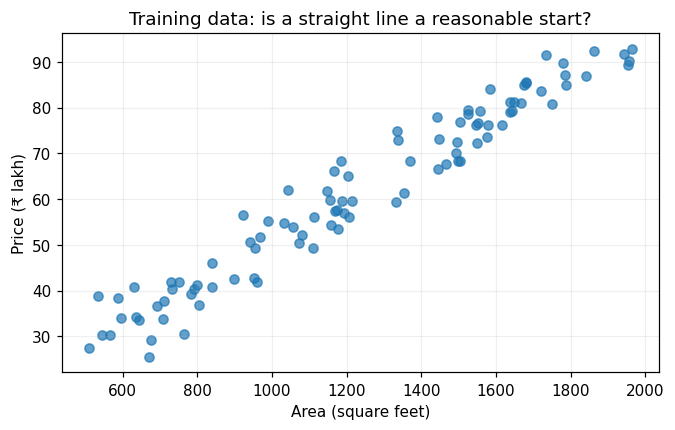

In [3]:
train_df, test_df = train_test_split(df, test_size=0.20, random_state=42)
X_train = train_df[["area_sqft"]]
y_train = train_df["price_lakh"]
X_test = test_df[["area_sqft"]]
y_test = test_df["price_lakh"]
features = ["area_sqft", "age_years"]

print("Training:", len(train_df), "| Test:", len(test_df))
assert set(train_df.index).isdisjoint(test_df.index)
assert not train_df.isna().any().any()
plt.scatter(X_train["area_sqft"], y_train, alpha=0.7)
plt.xlabel("Area (square feet)")
plt.ylabel("Price (₹ lakh)")
plt.title("Training data: is a straight line a reasonable start?")
plt.show()


## 4. Fit simple linear regression
$$\hat y=b_0+b_1\,\text{area}.$$
`fit` learns coefficients; `predict` applies them. The area coefficient is a predicted price change per additional square foot, not automatically a causal effect. The intercept may lack a practical interpretation because zero area lies outside the observed range.


In [4]:
model = LinearRegression().fit(X_train, y_train)
print(f"Intercept: {model.intercept_:.3f}")
print(f"Area coefficient: {model.coef_[0]:.5f} lakh per square foot")
print(f"100 additional sq ft changes prediction by ₹{100 * model.coef_[0]:.2f} lakh")
new_house = pd.DataFrame({"area_sqft": [1200]})
print(f"Prediction for 1200 sq ft: ₹{model.predict(new_house)[0]:.2f} lakh")


Intercept: 5.502
Area coefficient: 0.04541 lakh per square foot
100 additional sq ft changes prediction by ₹4.54 lakh
Prediction for 1200 sq ft: ₹60.00 lakh


**Expected:** intercept about 5.502, slope about 0.04541, prediction about ₹60.00 lakh. The area-only model omits age, so its parameters need not recover the generating formula exactly.


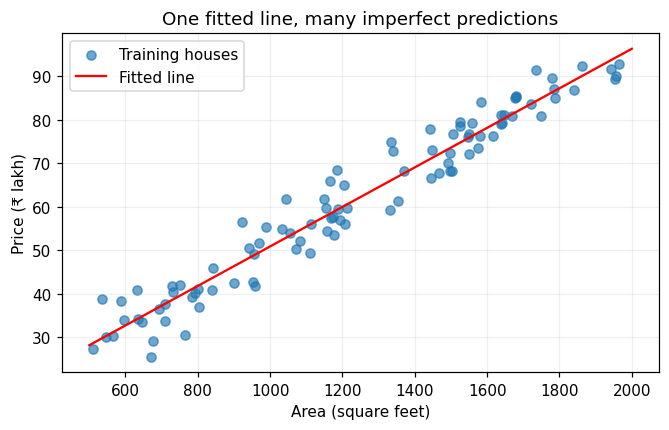

In [5]:
area_grid = pd.DataFrame({"area_sqft": np.linspace(500, 2000, 150)})
plt.scatter(X_train["area_sqft"], y_train, alpha=0.65, label="Training houses")
plt.plot(area_grid["area_sqft"], model.predict(area_grid), color="red", label="Fitted line")
plt.xlabel("Area (square feet)")
plt.ylabel("Price (₹ lakh)")
plt.title("One fitted line, many imperfect predictions")
plt.legend()
plt.show()


## 5. Understand metric choice before evaluating
For residuals $e_i=y_i-\hat y_i$:
$$\mathrm{MAE}=\frac1n\sum_i|e_i|,\qquad
\mathrm{RMSE}=\sqrt{\frac1n\sum_i e_i^2}.$$

| Metric | Use it for | Caution |
|---|---|---|
| MAE | Average absolute error in target units; roughly linear error cost | Does not make squared-loss training robust |
| RMSE | Extra emphasis on large errors in target units | A few large residuals can dominate |
| $R^2$ | A supporting unitless squared-error summary relative to target variation | Not accuracy; depends on the evaluated data |

Choose a primary metric based on the consequences of errors. For these prices, report MAE for interpretation, RMSE for large-error emphasis, and $R^2$ for context.

The next example uses two sets of errors with the **same MAE** but different RMSE.


In [6]:
y_toy = np.array([10., 20., 30., 40.])
error_patterns = {"Even errors": np.array([3., 3., 3., 3.]),
                  "One large error": np.array([0., 0., 0., 12.])}
rows = []
for name, errors in error_patterns.items():
    predictions = y_toy - errors
    rows.append({"Pattern": name,
                 "MAE": mean_absolute_error(y_toy, predictions),
                 "RMSE": np.sqrt(mean_squared_error(y_toy, predictions))})
print(pd.DataFrame(rows).to_string(index=False))


        Pattern  MAE  RMSE
    Even errors  3.0   3.0
One large error  3.0   6.0


Both MAE values are 3; RMSE rises from 3 to 6 when error is concentrated in one large miss.

For nonconstant targets,
$$R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}.$$
The mean $\bar y$ belongs to the **scored dataset**. Values of 1, 0, and below 0 mean perfect predictions, matching that mean reference, and worse than that reference. An $R^2$ of 0.9 does not mean every prediction is within 10%.

On the same scored targets, lower RMSE and higher $R^2$ produce identical model rankings. Across unrelated datasets, a higher $R^2$ can coexist with larger target-unit errors.


## 6. Add age: multiple linear regression
$$\hat y=b_0+b_1\,\text{area}+b_2\,\text{age}.$$
Interpret each coefficient **holding the other feature fixed**. Both houses below have area 1,200 square feet, so their prediction difference isolates the age term in the fitted rule.


In [7]:
multi_model = LinearRegression().fit(train_df[features], y_train)
coefficient_names = ["intercept", *features]
sklearn_betas = np.r_[multi_model.intercept_, multi_model.coef_]
print(pd.Series(sklearn_betas, index=coefficient_names).round(6).to_string())

houses = pd.DataFrame({"area_sqft": [1200, 1200], "age_years": [5, 25]})
houses["predicted_price_lakh"] = multi_model.predict(houses[features])
print("\nSame area, different ages:")
print(houses.round(2).to_string(index=False))


intercept    10.120112
area_sqft     0.045740
age_years    -0.343681

Same area, different ages:
 area_sqft  age_years  predicted_price_lakh
      1200          5                 63.29
      1200         25                 56.42


**Expected:** area coefficient about 0.0457, age coefficient about −0.3437, predicted prices about ₹63.29 and ₹56.42 lakh. Larger numerical coefficient magnitude does not imply greater importance because units differ.


## 7. Matrix method: compute the intercept and all slopes together
Add a column of ones for the intercept. With 96 training houses and two features:

- $X_b$ has shape $96\times3$: ones, area, age.
- $\boldsymbol b=[b_0,b_1,b_2]^T$ has three coefficients.
- $\hat{\boldsymbol y}=X_b\boldsymbol b$ gives all predictions.

The least-squares objective is $\min_b\|y-X_b b\|_2^2$. The normal equations are
$$X_b^TX_b\hat b=X_b^Ty.$$
When $X_b$ has full column rank:
$$\boxed{\hat b=(X_b^TX_b)^{-1}X_b^Ty.}$$

This is a mathematical expression, not a recommendation to calculate an inverse. Use `np.linalg.lstsq` on $X_b$ directly: it is more stable and also handles rank-deficient systems.


In [8]:
X_values = train_df[features].to_numpy()
y_values = y_train.to_numpy()
X_b = np.column_stack([np.ones(len(X_values)), X_values])

betas, residual_sums, rank, singular_values = np.linalg.lstsq(X_b, y_values, rcond=None)
print("Design-matrix shape:", X_b.shape, "| Rank:", rank)
print(pd.DataFrame({"NumPy lstsq": betas, "scikit-learn": sklearn_betas},
                   index=coefficient_names).round(6).to_string())
assert np.allclose(betas, sklearn_betas)
manual_predictions = X_b @ betas
assert np.allclose(manual_predictions, multi_model.predict(train_df[features]))
print("Both methods give matching coefficients and predictions.")
print("Manual prediction for area=1200, age=5:", np.array([[1., 1200., 5.]]) @ betas)


Design-matrix shape: (96, 3) | Rank: 3
           NumPy lstsq  scikit-learn
intercept    10.120112     10.120112
area_sqft     0.045740      0.045740
age_years    -0.343681     -0.343681
Both methods give matching coefficients and predictions.
Manual prediction for area=1200, age=5: [63.28926364]


`@` means matrix multiplication. Each design-matrix row multiplies the coefficient vector to produce one prediction. The first entry must be 1 to include the intercept.

**Placement in the teaching notes:** After the multiple-regression equation and coefficient interpretation, before assumptions. Keep this optional if matrix notation is new.


### Optional: connect the formula to computation
For this small, well-conditioned, full-rank example, `solve` can compute the normal equations without explicitly inverting a matrix. It still forms $X_b^TX_b$, which worsens conditioning; prefer `lstsq` for general use. The pseudoinverse is another least-squares representation.


In [9]:
beta_normal_equations = np.linalg.solve(X_b.T @ X_b, X_b.T @ y_values)
beta_pseudoinverse = np.linalg.pinv(X_b) @ y_values
print("Normal equations match lstsq:", np.allclose(beta_normal_equations, betas))
print("Pseudoinverse matches lstsq:", np.allclose(beta_pseudoinverse, betas))


Normal equations match lstsq: True
Pseudoinverse matches lstsq: True


### Optional: what if a feature is duplicated?
An exactly repeated area column makes the coefficient solution nonunique. Scaling does not repair exact redundancy. A least-squares solver still returns a solution, but the separate area coefficients no longer have a unique interpretation.


In [10]:
X_duplicate = np.column_stack([X_b, X_values[:, 0]])
beta_duplicate, _, rank_duplicate, _ = np.linalg.lstsq(X_duplicate, y_values, rcond=None)
print("Columns:", X_duplicate.shape[1], "| Independent columns:", rank_duplicate)
print("Coefficients [intercept, area, age, duplicate area]:", beta_duplicate.round(6))
print("Predictions still match:", np.allclose(X_duplicate @ beta_duplicate, manual_predictions))


Columns: 4 | Independent columns: 3
Coefficients [intercept, area, age, duplicate area]: [10.120112  0.02287  -0.343681  0.02287 ]
Predictions still match: True


## 8. Is scaling needed?
For ordinary unregularized OLS with an intercept and full-rank features, scaling is usually optional: it changes coefficient units, not the model's fitted prediction rule in exact arithmetic. Scaling may help numerical conditioning. Gradient-based solvers and coefficient-penalized methods such as Ridge/Lasso usually benefit from scaling.

Standardization uses training statistics:
$$z_j=(x_j-\mu_j)/s_j.$$
A pipeline keeps this transformation attached to the model. We leave the target in ₹ lakh. Fit scaling only on training inputs; inside CV, fit it separately within each fold.


In [11]:
scaled_model = make_pipeline(StandardScaler(), LinearRegression())
scaled_model.fit(train_df[features], y_train)

raw_predictions = multi_model.predict(train_df[features])
scaled_predictions = scaled_model.predict(train_df[features])
max_difference = np.max(np.abs(raw_predictions - scaled_predictions))
print("Largest training-prediction difference:", max_difference)
assert np.allclose(raw_predictions, scaled_predictions)

scaler = scaled_model.named_steps["standardscaler"]
scaled_regressor = scaled_model.named_steps["linearregression"]
print("Coefficients per one input standard deviation:", scaled_regressor.coef_.round(4))

# Recover coefficients in the original area/age units.
recovered_slopes = scaled_regressor.coef_ / scaler.scale_
recovered_intercept = scaled_regressor.intercept_ - recovered_slopes @ scaler.mean_
assert np.allclose(np.r_[recovered_intercept, recovered_slopes], sklearn_betas)
print("Recovered original-unit coefficients:", recovered_slopes.round(6))


Largest training-prediction difference: 2.842170943040401e-14
Coefficients per one input standard deviation: [18.5822 -3.1115]
Recovered original-unit coefficients: [ 0.04574  -0.343681]


The prediction difference should be near floating-point precision. The standardized coefficients differ because they describe one training standard deviation of input change. They do not automatically establish causal effects or a reliable feature-importance ranking. Scaling cannot make a curved relationship linear or eliminate outliers.


## 9. Diagnose training residuals
A residual is actual minus predicted price. Compare the two fixed models on training inputs to inspect their behavior. A curve can suggest missing structure; a funnel can suggest changing error spread. A plot with no obvious structure is not proof of correctness. Residual plots do not replace held-out evaluation.


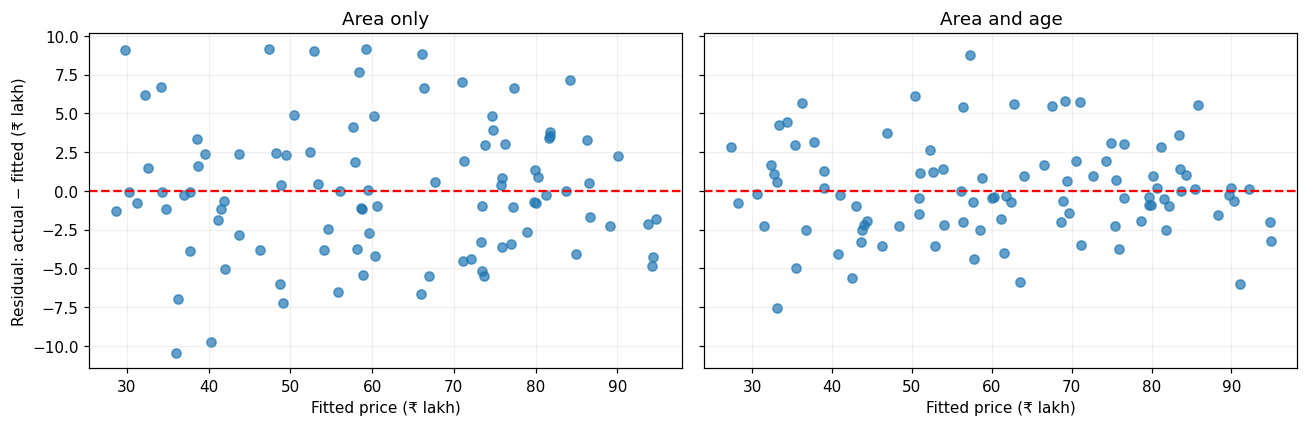

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, title, estimator, columns in [
    (axes[0], "Area only", model, ["area_sqft"]),
    (axes[1], "Area and age", multi_model, features)
]:
    fitted = estimator.predict(train_df[columns])
    residuals = y_train.to_numpy() - fitted
    ax.scatter(fitted, residuals, alpha=0.7)
    ax.axhline(0, color="red", linestyle="--")
    ax.set_xlabel("Fitted price (₹ lakh)")
    ax.set_title(title)
axes[0].set_ylabel("Residual: actual − fitted (₹ lakh)")
plt.tight_layout()
plt.show()


## 10. Training-only cross-validation
For a real feature/model decision, compare candidates using development data rather than repeated test checks. Here we compare our two predefined OLS recipes using the same five shuffled folds. For each fold, convert MSE to RMSE, then average those fold RMSE values. This differs slightly from taking the square root after averaging MSE values.

The dataset is small, so fold results vary. Standard deviation describes that variation; it is not a confidence interval.


In [13]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
candidates = {"Area only": ["area_sqft"], "Area and age": features}
cv_rows = []
for name, columns in candidates.items():
    fold_mse = -cross_val_score(LinearRegression(), train_df[columns], y_train,
                               cv=cv, scoring="neg_mean_squared_error")
    fold_rmse = np.sqrt(fold_mse)
    cv_rows.append({"Model": name, "Mean CV RMSE": fold_rmse.mean(),
                    "Fold RMSE std": fold_rmse.std()})
cv_results = pd.DataFrame(cv_rows).set_index("Model")
chosen_name = cv_results["Mean CV RMSE"].idxmin()
print(cv_results.round(3).to_string())
print("Training-only CV choice:", chosen_name)


              Mean CV RMSE  Fold RMSE std
Model                                    
Area only            4.373          0.184
Area and age         3.084          0.353
Training-only CV choice: Area and age


## 11. Ridge and Lasso: control coefficient size

Ordinary least squares minimizes squared training error. **Regularization** also discourages large coefficients, which can make a flexible or unstable fit less sensitive to training-data variation. It can help generalization, but is not guaranteed to beat OLS.

| Model | Extra penalty | Typical coefficient behavior | Useful when… |
|---|---|---|---|
| OLS | None | No shrinkage constraint | A simple, interpretable baseline is adequate |
| Ridge | L2: sum of squared slopes | Shrinks coefficients; generally retains nonzero slopes | Many predictors carry information, especially if related |
| Lasso | L1: sum of absolute slopes | Can make some slopes exactly zero | A sparse prediction rule is useful |

**Intuition:** Ridge turns coefficient sizes down; Lasso can also switch some terms off. A zero Lasso coefficient is a model choice, not proof that a feature is irrelevant or noncausal. With highly correlated inputs, which feature Lasso retains can be unstable.

### Objectives and alpha
With residuals $e_i=y_i-(b_0+\sum_jb_jz_{ij})$ on scaled features $z$:

- scikit-learn Ridge minimizes $\sum_i e_i^2+\alpha\sum_jb_j^2$.
- scikit-learn Lasso minimizes $\frac{1}{2n}\sum_i e_i^2+\alpha\sum_j|b_j|$.

The intercept is not included in these penalties. Within either model, a larger positive `alpha` means a stronger penalty. Their loss normalizations differ, so the same numerical alpha is **not** an equal-strength penalty across methods.

Too little regularization can leave an unstable fit; too much can underfit. Alpha is a **hyperparameter**, while coefficients are learned parameters. Use `LinearRegression` for the unregularized reference rather than `Lasso(alpha=0)`.

### Why we scale here
A coefficient's numerical size depends on input units. We standardize area and age before penalizing them so their units do not arbitrarily determine the relative penalty. Scaling now changes the regularized optimization problem; it is not merely a different representation of an identical OLS fit.

The pipeline must be inside the cross-validation search: each fold learns scaling from its own training portion. The target remains in ₹ lakh.


### Tune alpha with training data only
Try a small logarithmic grid: each step multiplies alpha rather than adding a fixed amount. `GridSearchCV` compares candidates with the same five folds, using **mean fold RMSE**, and refits the winning pipeline on all training houses. Test data does not participate in alpha selection.

The grids below intentionally span weak to strong penalties. They are starting points, not universal defaults. If a CV minimum falls at a grid edge, consider expanding that edge using training-only CV before a final test evaluation. Here the low-alpha edge can simply indicate that little regularization is useful.


In [14]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

regularization_cv = KFold(n_splits=5, shuffle=True, random_state=42)
search_specs = {
    "Ridge": (Ridge(), np.logspace(-3, 4, 15)),
    "Lasso": (Lasso(max_iter=20000, tol=1e-7), np.logspace(-3, 1.5, 16))
}
searches, tuned_models, regularization_rows = {}, {}, []
for name, (regressor, alpha_grid) in search_specs.items():
    pipeline = Pipeline([("scale", StandardScaler()), ("regressor", regressor)])
    search = GridSearchCV(
        pipeline, {"regressor__alpha": alpha_grid},
        cv=regularization_cv, scoring="neg_root_mean_squared_error", refit=True
    )
    search.fit(train_df[features], y_train)
    searches[name] = search
    tuned_models[name] = search.best_estimator_
    regularization_rows.append({
        "Model": name,
        "Best alpha": search.best_params_["regressor__alpha"],
        "Mean CV RMSE": -search.best_score_
    })
regularization_results = pd.DataFrame(regularization_rows).set_index("Model")
print(regularization_results.round(5).to_string())


       Best alpha  Mean CV RMSE
Model                          
Ridge     0.03162       3.08433
Lasso     0.00100       3.08436


**Read the output:** Lower CV RMSE is better. The winning alpha is refitted automatically because `refit=True`. `max_iter` and `tol` give Lasso's numerical solver enough iterations and a tighter stopping tolerance; they are not regularization strengths.

This dataset has only two genuinely useful features and many more observations than coefficients. Small penalties and little improvement over OLS are entirely reasonable. Do not assume regularization must win, or change the test data to make it win.


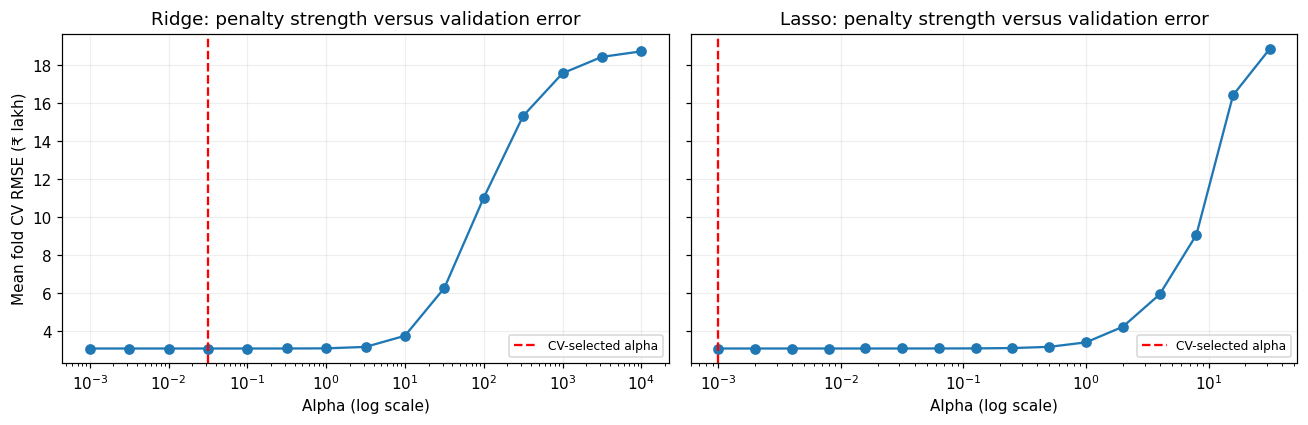

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, name in zip(axes, ["Ridge", "Lasso"]):
    search = searches[name]
    alphas = np.array(search.cv_results_["param_regressor__alpha"], dtype=float)
    cv_rmse = -search.cv_results_["mean_test_score"]
    ax.semilogx(alphas, cv_rmse, "o-")
    ax.axvline(search.best_params_["regressor__alpha"], color="red",
               linestyle="--", label="CV-selected alpha")
    ax.set_xlabel("Alpha (log scale)")
    ax.set_title(f"{name}: penalty strength versus validation error")
    ax.legend(fontsize=8)
axes[0].set_ylabel("Mean fold CV RMSE (₹ lakh)")
plt.tight_layout()
plt.show()


A large-alpha error increase is evidence of excessive shrinkage and underfitting. Each model's alpha axis has its own scale. In `cv_results_`, “test score” means the held-out **CV fold** score; it does not refer to our separate `test_df`.


### Inspect coefficients in comparable units
For the next table, fit OLS on the same standardized inputs as Ridge and Lasso. A standardized-input coefficient describes the predicted target change for one training standard deviation of that input, holding other inputs fixed. Coefficients remain in target units because we did not scale price.


In [16]:
standardized_ols = Pipeline([
    ("scale", StandardScaler()), ("regressor", LinearRegression())
]).fit(train_df[features], y_train)
standardized_coefficients = pd.DataFrame({
    "OLS": standardized_ols.named_steps["regressor"].coef_,
    **{name: estimator.named_steps["regressor"].coef_
       for name, estimator in tuned_models.items()}
}, index=features)
print("Coefficients for standardized inputs:")
print(standardized_coefficients.round(5).to_string())

original_unit_rows = []
for name, estimator in {"OLS": standardized_ols, **tuned_models}.items():
    scaler = estimator.named_steps["scale"]
    regressor = estimator.named_steps["regressor"]
    slopes = regressor.coef_ / scaler.scale_
    intercept = regressor.intercept_ - slopes @ scaler.mean_
    original_unit_rows.append({"Model": name, "Intercept": intercept,
                               **dict(zip(features, slopes))})
print("\nCoefficients converted back to original feature units:")
print(pd.DataFrame(original_unit_rows).set_index("Model").round(6).to_string())


Coefficients for standardized inputs:
                OLS     Ridge     Lasso
area_sqft  18.58220  18.57603  18.58116
age_years  -3.11149  -3.11020  -3.11045

Coefficients converted back to original feature units:
       Intercept  area_sqft  age_years
Model                                 
OLS    10.120112   0.045740  -0.343681
Ridge  10.136708   0.045724  -0.343538
Lasso  10.121586   0.045737  -0.343565


At the selected alpha, Lasso may retain **both** features, since both carry signal. It does not have to select fewer features every time. Also, individual coefficient magnitudes need not decrease monotonically when predictors are correlated; the paths below show the behavior in this particular dataset.


### See shrinkage across a wider range of alpha values
These are **training-fit visualizations**, not another test-based search. We include deliberately strong penalties to make shrinkage and Lasso's exact zeros visible. A visually simpler fit is not automatically a better predictor.


Ridge, largest alpha=100000.0, coefficients=[ 0.0177  -0.00223]
Lasso, largest alpha=100.0, coefficients=[0. 0.]


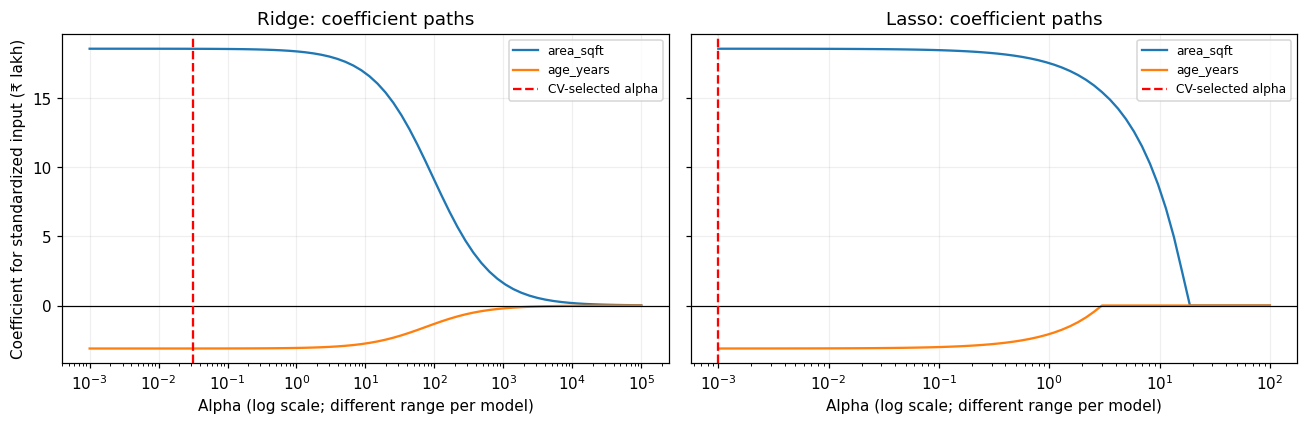

In [17]:
path_specs = {
    "Ridge": (np.logspace(-3, 5, 70), lambda a: Ridge(alpha=a)),
    "Lasso": (np.logspace(-3, 2, 70),
              lambda a: Lasso(alpha=a, max_iter=20000, tol=1e-7))
}
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, (alphas, make_regressor)) in zip(axes, path_specs.items()):
    paths = []
    for alpha in alphas:
        estimator = Pipeline([
            ("scale", StandardScaler()), ("regressor", make_regressor(alpha))
        ]).fit(train_df[features], y_train)
        paths.append(estimator.named_steps["regressor"].coef_)
    paths = np.asarray(paths)
    for j, feature in enumerate(features):
        ax.semilogx(alphas, paths[:, j], label=feature)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(searches[name].best_params_["regressor__alpha"],
               color="red", linestyle="--", label="CV-selected alpha")
    ax.set_title(f"{name}: coefficient paths")
    ax.set_xlabel("Alpha (log scale; different range per model)")
    ax.legend(fontsize=8)
    print(f"{name}, largest alpha={alphas[-1]:.1f}, coefficients={paths[-1].round(5)}")
axes[0].set_ylabel("Coefficient for standardized input (₹ lakh)")
plt.tight_layout()
plt.show()


**What to notice:** Ridge coefficients approach zero as the penalty grows. Lasso can reach exactly zero at a finite alpha. At very large Lasso alpha, both informative predictors can be discarded and predictions collapse to the fitted intercept: the training mean. This demonstrates underfitting, not successful discovery of irrelevant features.

### Select a recipe before looking at test errors
Combine the original OLS CV results with the tuned Ridge and Lasso CV scores. The two searches used the same shuffled folds and the same mean-fold-RMSE criterion. These are development scores used for selection; the best score can be optimistic after a search. The separate final test gives an additional check.


In [18]:
all_cv_results = pd.concat([
    cv_results[["Mean CV RMSE"]],
    regularization_results[["Mean CV RMSE"]]
])
chosen_name = all_cv_results["Mean CV RMSE"].idxmin()
print(all_cv_results.round(4).to_string())
print("Selected using training-only CV:", chosen_name)


              Mean CV RMSE
Model                     
Area only           4.3734
Area and age        3.0844
Ridge               3.0843
Lasso               3.0844
Selected using training-only CV: Ridge


## 12. Final held-out evaluation and a practical baseline
All fits, scaling demonstrations, and CV comparisons above used training data only. Now report held-out performance for the two OLS models, the CV-tuned Ridge and Lasso models, and a baseline. The selected model was chosen **before** looking at these test results. Do not revise the model repeatedly using this table.

The baseline uses the **training mean**, available at prediction time. Its test $R^2$ need not equal zero, because the score's mean reference uses the test targets' mean.


In [19]:
baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)

def regression_metrics(actual, predicted):
    return {"MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
            "R2": r2_score(actual, predicted)}

fitted_models = {"Area only": (model, ["area_sqft"]),
                 "Area and age": (multi_model, features),
                 "Training-mean baseline": (baseline, ["area_sqft"])}
fitted_models.update({name: (estimator, features)
                      for name, estimator in tuned_models.items()})
evaluation_rows = []
for name, (estimator, columns) in fitted_models.items():
    train_prediction = estimator.predict(train_df[columns])
    test_prediction = estimator.predict(test_df[columns])
    metrics = regression_metrics(y_test, test_prediction)
    evaluation_rows.append({"Model": name,
                            "Train RMSE": np.sqrt(mean_squared_error(y_train, train_prediction)),
                            "Test MAE": metrics["MAE"], "Test RMSE": metrics["RMSE"],
                            "Test R2": metrics["R2"]})
print(pd.DataFrame(evaluation_rows).set_index("Model").round(3).to_string())
print("CV-selected model evaluated above:", chosen_name)


                        Train RMSE  Test MAE  Test RMSE  Test R2
Model                                                           
Area only                    4.344     4.090      5.276    0.922
Area and age                 3.035     2.779      3.413    0.967
Training-mean baseline      18.955    16.879     19.584   -0.079
Ridge                        3.035     2.782      3.413    0.967
Lasso                        3.035     2.780      3.413    0.967
CV-selected model evaluated above: Ridge


**Interpret the original area-only result:** MAE ≈ ₹4.09 lakh, RMSE ≈ ₹5.28 lakh, $R^2$ ≈ 0.922. The baseline's test RMSE is ≈ ₹19.58 lakh. In this synthetic setting, adding the relevant age feature should improve predictions further. This is not a guarantee that adding arbitrary features helps.

A high $R^2$ and beating a baseline do not establish real-world suitability. Consider whether errors are acceptable, inputs are representative, and new buildings follow similar relationships.

**Regularization result:** OLS with area and age, Ridge, and Lasso have nearly identical errors here. The CV-selected Ridge alpha is small. A tiny numerical CV advantage is not strong evidence of a practically better model; it is reasonable to prefer a simpler recipe when results are effectively tied.


 Actual price  Predicted price  Residual
        87.59            84.36      3.23
        39.03            44.44     -5.42
        37.17            39.03     -1.86
        86.35            86.08      0.27
        61.31            61.59     -0.28
        62.81            68.58     -5.77
        44.22            40.48      3.74
        63.87            56.67      7.20


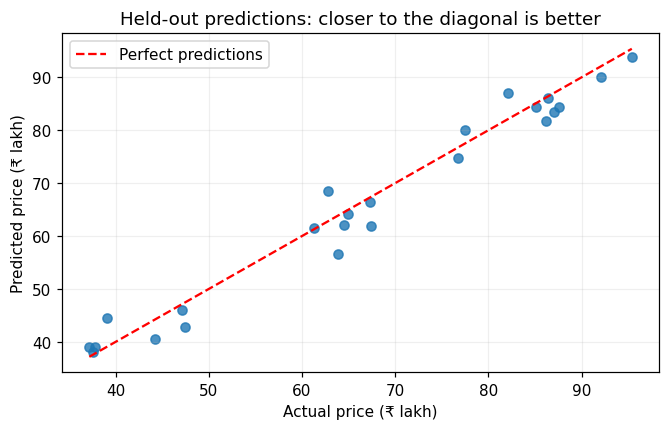

In [20]:
selected_estimator, selected_columns = fitted_models[chosen_name]
selected_predictions = selected_estimator.predict(test_df[selected_columns])
comparison = pd.DataFrame({"Actual price": y_test.to_numpy(),
                           "Predicted price": selected_predictions})
comparison["Residual"] = comparison["Actual price"] - comparison["Predicted price"]
print(comparison.head(8).round(2).to_string(index=False))

plt.scatter(y_test, selected_predictions, alpha=0.8)
low = min(y_test.min(), selected_predictions.min())
high = max(y_test.max(), selected_predictions.max())
plt.plot([low, high], [low, high], "r--", label="Perfect predictions")
plt.xlabel("Actual price (₹ lakh)")
plt.ylabel("Predicted price (₹ lakh)")
plt.title("Held-out predictions: closer to the diagonal is better")
plt.legend()
plt.show()


## 13. Optional: one unusual observation can move the line
This independent toy example does not change the house models. Squared-loss fitting can be sensitive to an unusual observation. Inspect such a point rather than deleting it automatically: it might be a mistake, a valid rare case, or a sign of missing information.


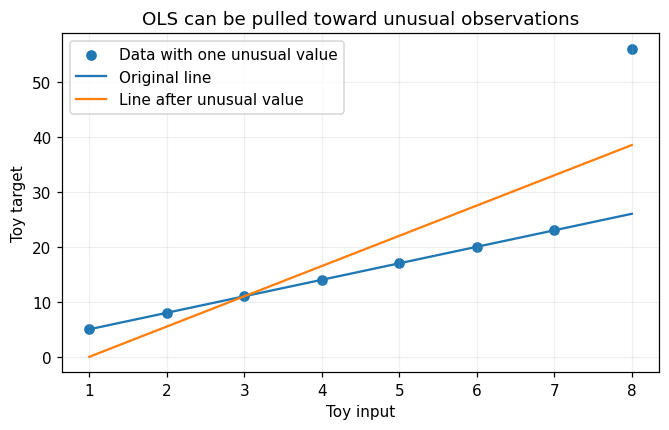

In [21]:
x_small = np.arange(1., 9.).reshape(-1, 1)
y_clean = 2 + 3 * x_small[:, 0]
y_unusual = y_clean.copy()
y_unusual[-1] += 30
fit_clean = LinearRegression().fit(x_small, y_clean)
fit_unusual = LinearRegression().fit(x_small, y_unusual)

plt.scatter(x_small[:, 0], y_unusual, label="Data with one unusual value")
plt.plot(x_small[:, 0], fit_clean.predict(x_small), label="Original line")
plt.plot(x_small[:, 0], fit_unusual.predict(x_small), label="Line after unusual value")
plt.xlabel("Toy input")
plt.ylabel("Toy target")
plt.title("OLS can be pulled toward unusual observations")
plt.legend()
plt.show()


## 14. Practice and discussion
1. Interpret the area-only coefficient for 100 additional square feet.
2. Explain why positive residuals mean underprediction.
3. Which metric distinguishes `[3,3,3,3]` from `[0,0,0,12]` more strongly?
4. Explain why standardized OLS coefficients change while predictions stay the same.
5. Why is the first design-matrix column all ones?
6. Why prefer `lstsq` over explicitly computing an inverse?
7. Is a prediction for a 10,000-square-foot house trustworthy here?
8. Why must a model's test score not determine repeated model revisions?

9. Why does Ridge/Lasso use a scaler inside the CV pipeline?
10. Does Lasso always remove at least one feature?
11. Why should we not compare equal numerical alpha values as equal-strength Ridge and Lasso penalties?

**Optional experiments:** On a separate synthetic dataset or training-only validation split, change noise, sample size, or candidate features and compare results. Keep the original final test protected. If you repeatedly tune after seeing it, use fresh held-out data for a new final claim.


### Answer cues
1. About ₹4.54 lakh higher under the fitted area-only rule.
2. Actual minus prediction is positive when the prediction is too low.
3. RMSE: 3 versus 6, while both MAE values are 3.
4. Scaling changes units and the intercept representation; OLS compensates with coefficients.
5. It multiplies the intercept, adding the same constant to every prediction.
6. It avoids forming an inverse and the less stable normal-equation product; it handles rank deficiency.
7. It is far outside the observed area range: extrapolation requires caution.
8. Test-guided revisions make the test set part of development.

9. Penalties depend on coefficient units; fitting the scaler within each fold avoids validation leakage.
10. No. At a small or selected alpha, all features may remain; a very large alpha can even discard useful ones.
11. Their penalty forms and loss normalizations differ. Tune each model independently using validation data.

### References
- [scikit-learn LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)
- [Regression metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics)
- [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)
- [NumPy lstsq](https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html)

- [scikit-learn Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html)
- [scikit-learn Lasso](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html)
